<a href="https://colab.research.google.com/github/AleynaCifcibasi/Python-ile-Machine-Learning-al-malar-ve-projeleri/blob/main/Python_Oturum_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#CNN

##Kütüphane


In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, ReLU
import matplotlib.pyplot as plt

##Veri

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [3]:
X_train.shape

(60000, 28, 28)

In [4]:
X_train = X_train.reshape(-1,28,28,1) / 255
X_test = X_test.reshape(-1,28,28,1) / 255

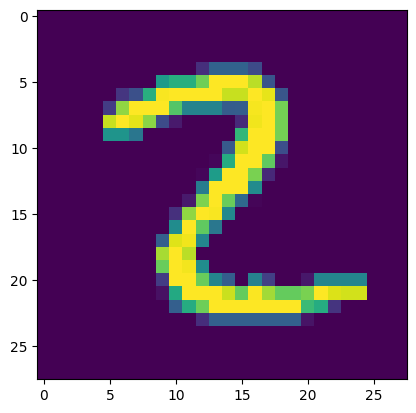

In [5]:
plt.imshow(X_train[76])

##Model

In [6]:
cnn_model = Sequential([
    Conv2D(32,(3,3), activation='relu',input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(64,(3,3)),
    ReLU(),
    MaxPooling2D((2,2)),
    Conv2D(128,(3,3)),
    ReLU(),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(64,activation='relu'),
    Dense(32,activation='relu'),
    Dense(10,activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

##Metin

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
cnn_model.fit(X_train,y_train, epochs=200,batch_size=64,validation_data=(X_test, y_test))
cnn_model.save('/content/drive/MyDrive/Tech İstanbul/cnn.keras')

Epoch 1/200
938/938 ━━━━━━━━━━━━━━━━━━━━ 24s 15ms/step - accuracy: 0.9134 - loss: 0.2785 - val_accuracy: 0.9716 - val_loss: 0.0982
Epoch 2/200
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9748 - loss: 0.0836 - val_accuracy: 0.9829 - val_loss: 0.0564
Epoch 3/200
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9813 - loss: 0.0611 - val_accuracy: 0.9807 - val_loss: 0.0616
Epoch 4/200
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9858 - loss: 0.0464 - val_accuracy: 0.9865 - val_loss: 0.0449
Epoch 5/200
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9886 - loss: 0.0377 - val_accuracy: 0.9851 - val_loss: 0.0490
Epoch 6/200
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9897 - loss: 0.0331 - val_accuracy: 0.9829 - val_loss: 0.0537
Epoch 7/200
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9915 - loss: 0.0267 - val_accuracy: 0.9873 - val_loss: 0.0463
Epoch 8/200
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9922 - loss: 0.0237 - val_ac

##Filtre Görselleştirme

In [11]:
layer_index = 5
layer = cnn_model.layers[layer_index]

In [12]:
filters, biases = layer.get_weights()

In [13]:
n_filters = filters.shape[3]

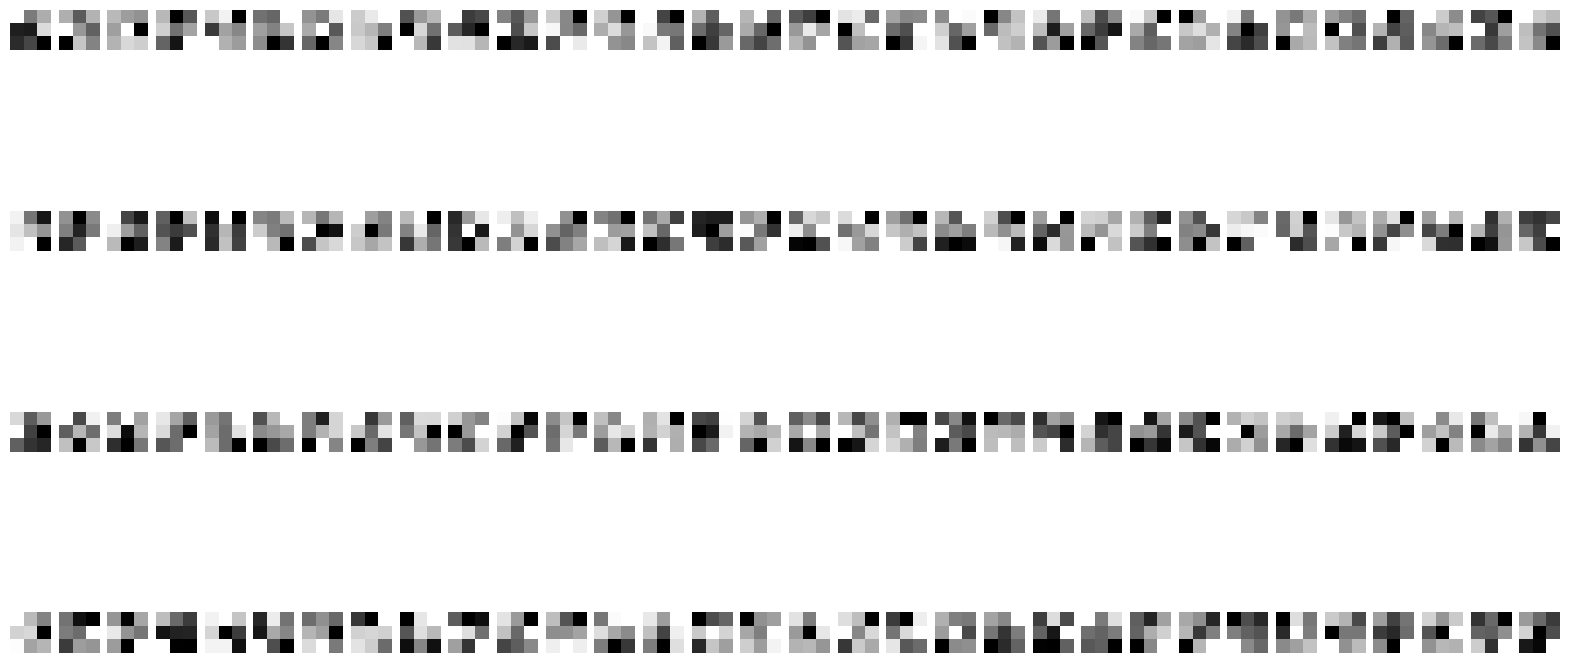

In [14]:
plt.figure(figsize=(20,10))

for i in range(n_filters):
  f = filters[:,:,:,i]
  plt.subplot(4,32,i+1)
  plt.imshow(f[:,:,0],cmap='gray')
  plt.axis('off')
plt.show()

##Gerçek Zamanlı Test

In [15]:
from PIL import Image
import numpy as np

In [16]:
def tahmin(image_path):
  img = Image.open(image_path).convert('L')
  img = img.resize((28,28))
  img_array = np.array(img)

  img_array = img_array.reshape(-1,28,28,1)/255

  prediction = cnn_model.predict(img_array)

  predicted_number = np.argmax(prediction)

  print(predicted_number)

  plt.imshow(img,cmap='gray')
  plt.title(f"Tahmin : {predicted_number}")
  plt.axis('off')
  plt.show()

In [18]:
giris = input("Tahmin etmek istediğiniz görselin dosya yolunu giriniz : ")
tahmin(giris)

Tahmin etmek istediğiniz görselin dosya yolunu giriniz : 1


FileNotFoundError: [Errno 2] No such file or directory: '1'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')